# Ideas

1. **Image Preprocessing**
    -   **Dataset Augmentation**
        *   x10 the training dataset
    -   Grayscaling
        *   Primarily reduce the computational power
2. **Intuitively Group Age Classes**
    -   Roblox: 5-8, 9-12, 13-15, 16-17, 18-20, and 21+
    -   Business-wise, we have to add more label for 21+
    -   Suggestion for 21+ group: 21-27, 28-45, 46-65, 66+
        -   21-27 years: Categorized as mature adults (8:23).
        -   28-45 years: Representing the adult stage of life (8:26).
        -   46-65 years: Distinguished by the appearance of more pronounced aging features (8:29).
        -   66+ years: Represented by features like graying hair and aging skin (8:36).
3. Use CNN-Based Deep Learning Aproach


Concluded labels: 1-4, 5-8, 9-12, 13-15, 16-17, 18-20, 21-27, 28-45, 46-65, 66+

# Import Libraries and Setup Environments

In [18]:
# Standard libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from keras import mixed_precision, layers, models
from keras.models import Sequential, Model
from keras.layers import Conv2D, MaxPooling2D, AveragePooling2D, GlobalAveragePooling2D, Flatten, Dense, Dropout, Input, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img # From old Keras' API. For data augmentation, Keras has imported a new API in TensorFlow 2.x. So, we can use it directly from TensorFlow.
from keras.utils import to_categorical, plot_model
from keras.optimizers import SGD, Adam
from keras.callbacks import ReduceLROnPlateau, EarlyStopping
from keras.applications import VGG16, MobileNetV2
from keras.applications.vgg16 import preprocess_input as vgg_preprocess
from keras.applications.mobilenet_v2 import preprocess_input as mobile_preprocess

# Others:
from pathlib import Path
import os
#import cv2
from tqdm.notebook import tqdm
import imagehash 
from PIL import Image

In [19]:
gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow version:", tf.__version__)
print("GPU devices:", gpus)

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [20]:
# This will reduce the VRAM consumed
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
    print("GPU Memory Growth Enabled!")

GPU Memory Growth Enabled!


In [21]:
# For strong GPUs, execute this code cell to turn on FP16 and reduce VRAM usage consumed
mixed_precision.set_global_policy("mixed_float16")

# Load the Dataset

In [22]:
import kagglehub

# Find the root folder of the project
PROJECT_ROOT = Path.cwd()

# This is for notebooks that is opened in notebooks/ (folder)
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# The function to download dataset immediately into data/raw
def download_dataset(kaggle_url: str, folder_name: str) -> Path:
    """Download a Kaggle dataset into its own directory.
    - kaggle_url: author/dataset-name (on Kaggle)
    - folder_name: the name of the folder that will hold the dataset"""
    output_dir = DATA_DIR / folder_name
    output_dir.mkdir(parents=True, exist_ok=True)

    path = kagglehub.dataset_download(
        kaggle_url,
        output_dir=str(output_dir),
        force_download=True
    )

    print(f"Dataset: {kaggle_url}")
    print(f"Saved to: {path}")

    return Path(path)

In [23]:
utk_path = download_dataset("jangedoo/utkface-new", "utkface")
#facial_age_v1_path = download_dataset("frabbisw/facial-age","facial-age-v1")

100%|██████████| 331M/331M [01:29<00:00, 3.89MB/s] 

Extracting files...


Dataset: jangedoo/utkface-new
Saved to: /home/sisi/projects/age-estimation/data/raw/utkface


In [24]:
utk_path = '/home/sisi/projects/age-estimation/data/raw/utkface'
BASE_DIR = os.path.join(utk_path, "UTKFace")
print(BASE_DIR)

/home/sisi/projects/age-estimation/data/raw/utkface/UTKFace


In [25]:
image_paths = []
age_labels = []

for filename in tqdm(os.listdir(BASE_DIR)):
    image_path = os.path.join(BASE_DIR, filename)
    components = filename.split("_")
    age = int(components[0])
    image_paths.append(image_path)
    age_labels.append(age)

  0%|          | 0/23708 [00:00<?, ?it/s]

In [26]:
df = pd.DataFrame()
df['image'], df['age'] = image_paths, age_labels
df.head()

,image,age
0,/home/sisi/projects/age-estimation/data/raw/ut...,39
1,/home/sisi/projects/age-estimation/data/raw/ut...,23
2,/home/sisi/projects/age-estimation/data/raw/ut...,26
3,/home/sisi/projects/age-estimation/data/raw/ut...,31
4,/home/sisi/projects/age-estimation/data/raw/ut...,42


# EDA

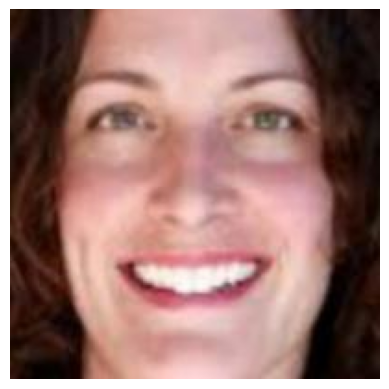

In [27]:
img = Image.open(df['image'][0])
plt.axis('off')
plt.imshow(img) # Semi-colon prevents the console to show anything else but the image

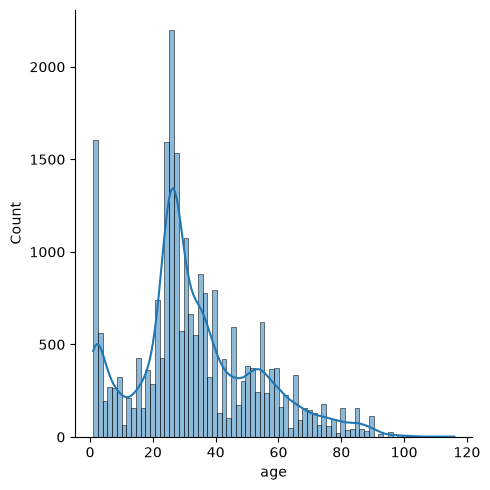

In [28]:
sns.displot(df['age'], kde=True)

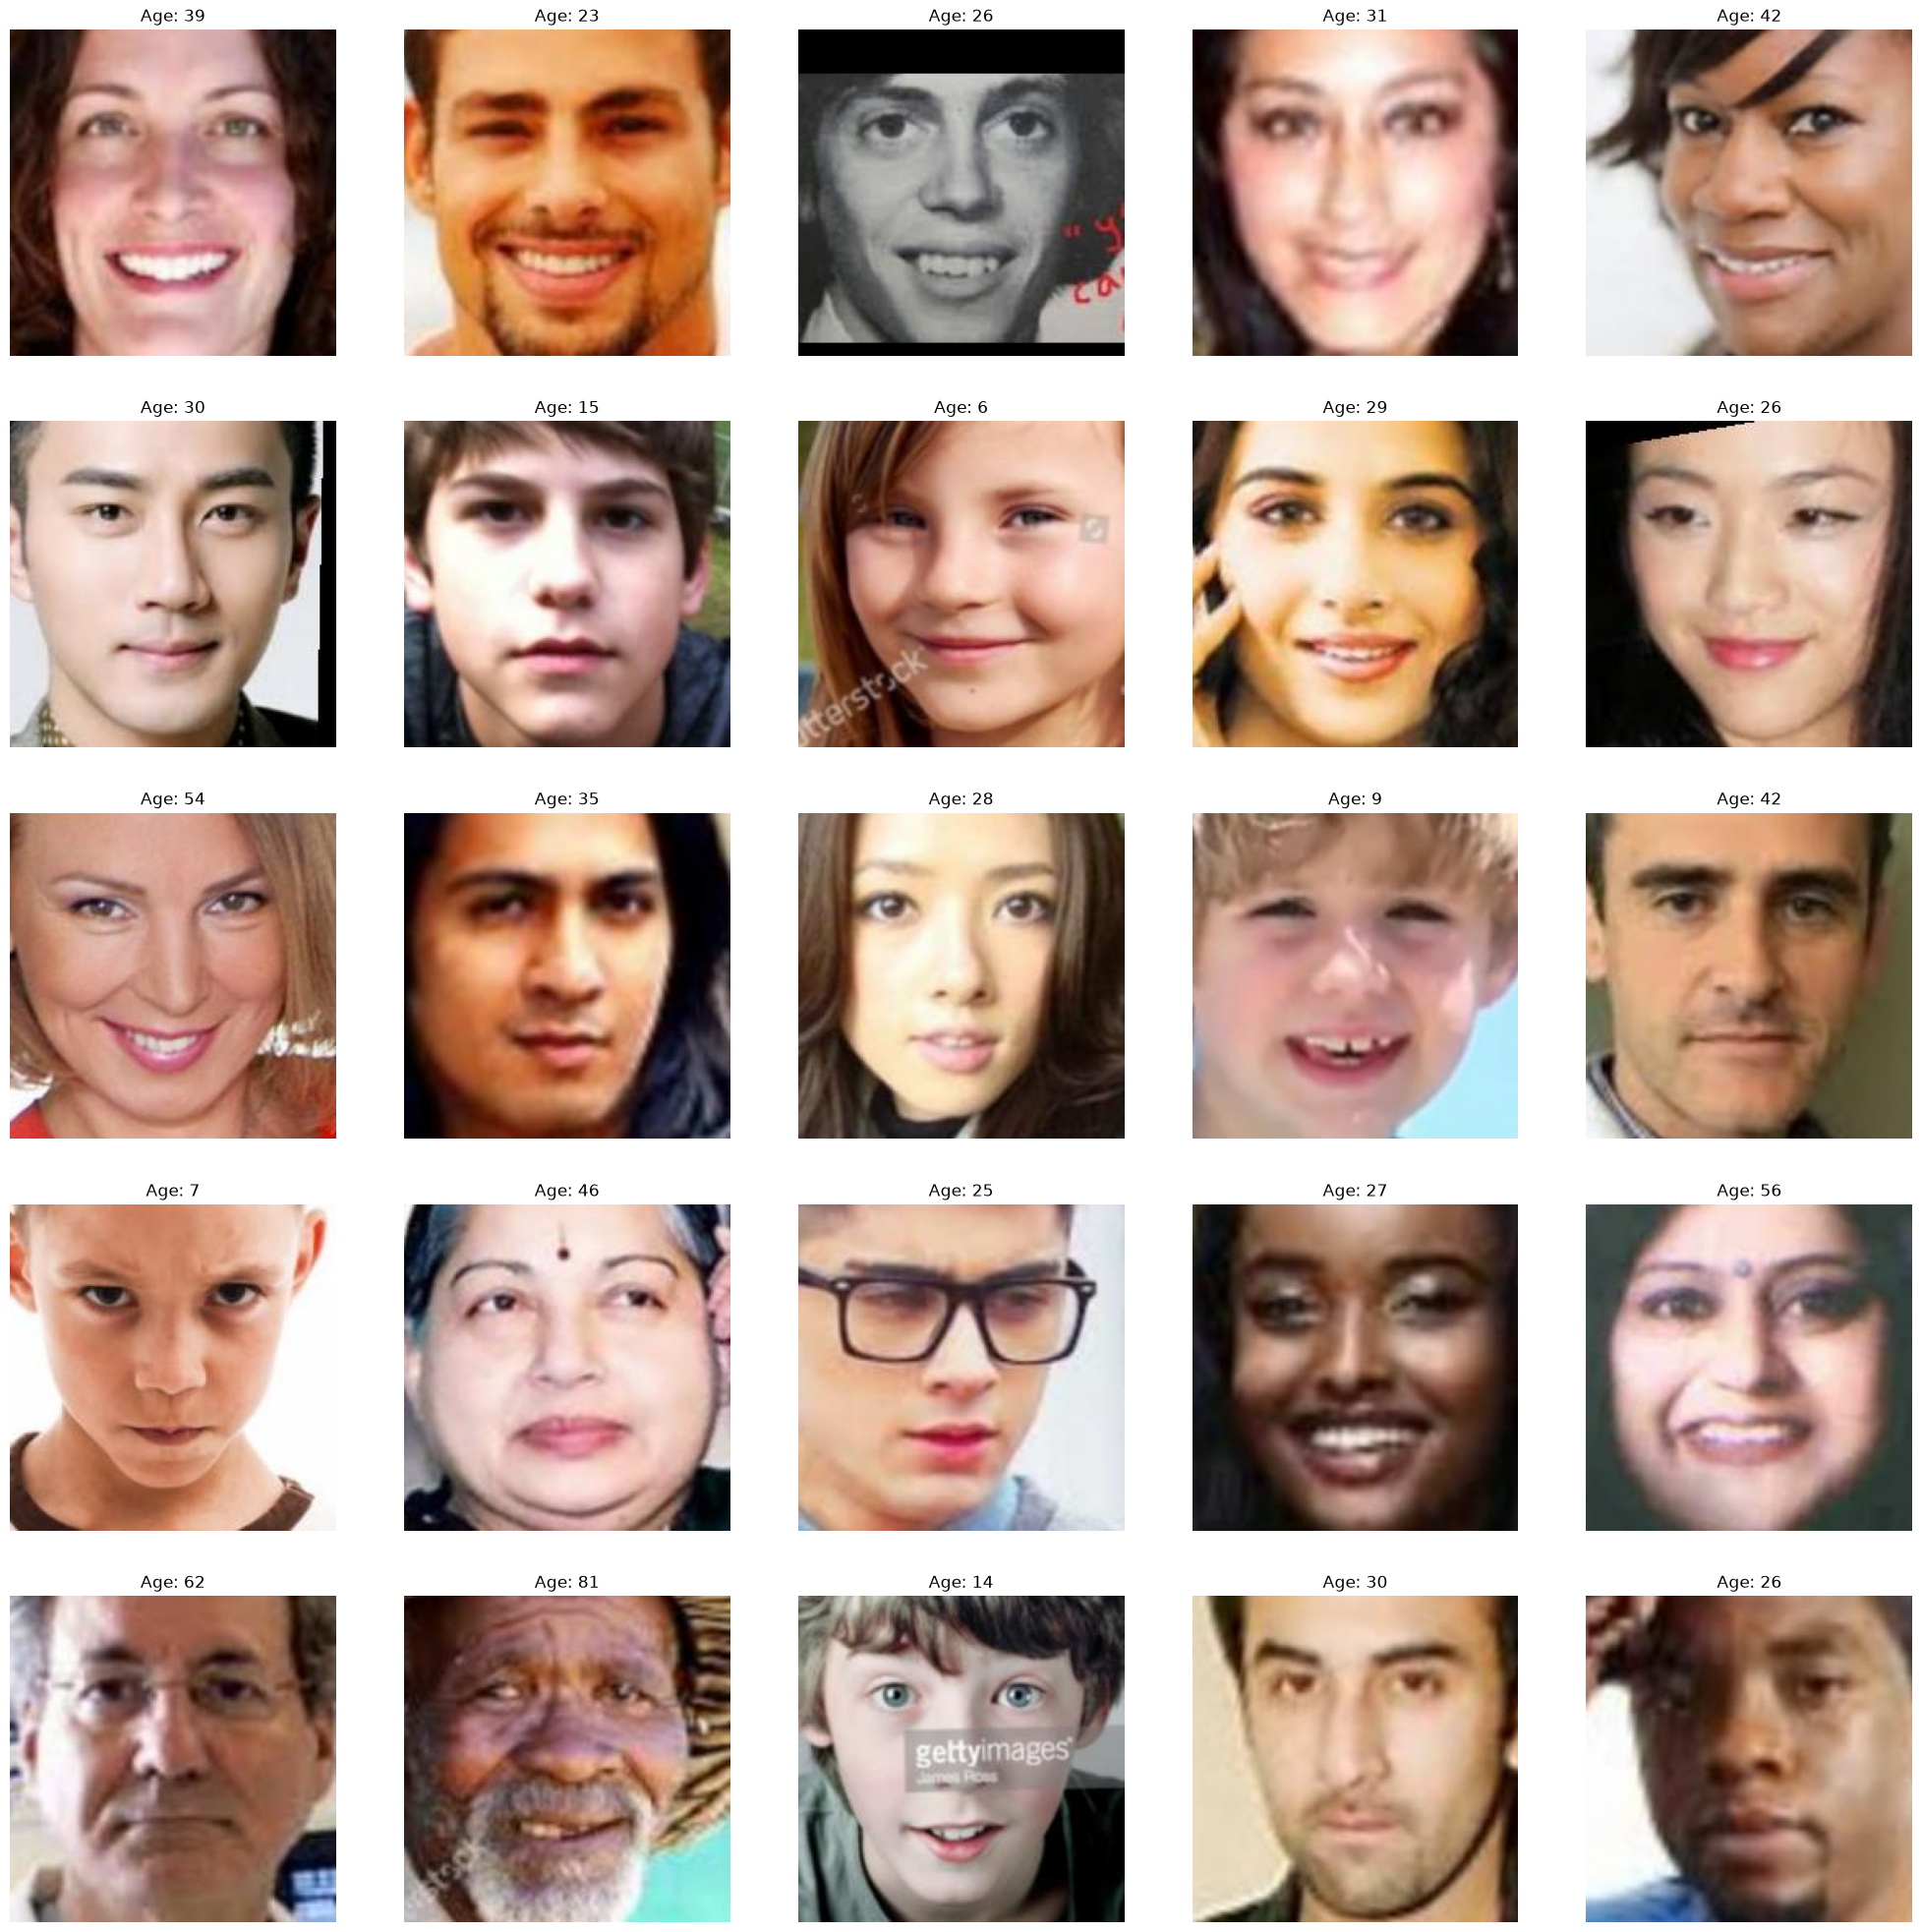

In [29]:
plt.figure(figsize=(25, 25))
files = df.iloc[0:25]

for index, file, age in files.itertuples():
    plt.subplot(5, 5, index+1)
    img = load_img(file)
    img = np.array(img)
    plt.imshow(img)
    plt.title(f"Age: {age}")
    plt.axis('off')

# Feature Extraction

In [30]:
def map_age_to_group(age):
    if age <= 4:
        return 0
    elif age <= 8:
        return 1
    elif age <= 12:
        return 2
    elif age <= 15:
        return 3
    elif age <= 17:
        return 4
    elif age <= 20:
        return 5
    elif age <= 27:
        return 6
    elif age <= 45:
        return 7
    elif age <= 65:
        return 8
    else:
        return 9

# Map each age to its group index (0-9)
df['age_group'] = df['age'].apply(map_age_to_group)

# Convert indices to one-hot encoded representation (10 classes)
y_age_cat = to_categorical(df['age_group'], num_classes=10)

print("Original labels sample:", df['age'].values[:5])
print("Mapped group indices sample:", df['age_group'].values[:5])
print("One-hot encoded targets shape:", y_age_cat.shape)

Original labels sample: [39 23 26 31 42]
Mapped group indices sample: [7 6 6 7 7]
One-hot encoded targets shape: (23708, 10)


In [31]:
def extract_features(images, size:int):
    features = []
    for image in tqdm(images):
        img = load_img(image, color_mode="grayscale")

        # Use Image.Resampling.LANCZOS instead of deprecated Image.ANTIALIAS
        resample_filter = Image.Resampling.LANCZOS if hasattr(Image, 'Resampling') else Image.ANTIALIAS
        img = img.resize((size, size), resample_filter)

        img = np.array(img)
        features.append(img)

    features = np.array(features)
    features = features.reshape(len(features), size, size, 1)

    return features

In [32]:
X = extract_features(df['image'], size=100)

  0%|          | 0/23708 [00:00<?, ?it/s]

In [33]:
X.shape

(23708, 100, 100, 1)

In [34]:
# Normalization
X = X.astype('float32') / 255.0

y_age = np.array(df['age'])

In [35]:
X_train, X_holdout, y_train, y_holdout, groups_train, groups_holdout = train_test_split(
    X,
    y_age_cat,
    df["age_group"].to_numpy(),
    test_size=0.2,
    stratify=df["age_group"],
    random_state=42,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_holdout,
    y_holdout,
    test_size=0.5,
    stratify=groups_holdout,
    random_state=42,
)

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

Train: 18966 | Validation: 2371 | Test: 2371


In [36]:
simple_model = Sequential()

simple_model.add(Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(100, 100, 1)))
simple_model.add(MaxPooling2D(pool_size=(2, 2)))
simple_model.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
simple_model.add(MaxPooling2D(pool_size=(2, 2)))
simple_model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
simple_model.add(MaxPooling2D(pool_size=(2, 2)))
simple_model.add(Conv2D(256, (3, 3), padding='same', activation='relu'))
simple_model.add(MaxPooling2D(pool_size=(2, 2)))

simple_model.add(Flatten())
simple_model.add(Dense(256, activation='relu'))
simple_model.add(Dense(32, activation='relu'))
simple_model.add(Dense(10, activation='softmax'))

/home/sisi/projects/age-estimation/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1792120667.003194    4551 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13549 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Ti SUPER, pci bus id: 0000:01:00.0, compute capability: 8.9


In [37]:
simple_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 100, 100, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 25, 25, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,755,946 (10.51 MB)

 Trainable params: 2,755,946 (10.51 MB)

 Non-trainable params: 0 (0.00 B)

In [38]:
plot_model(simple_model, dpi=64)

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


In [39]:
simple_model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)
# Add early stopping to prevent overfitting and save the best model
early_stop = EarlyStopping(
    monitor='val_loss',             # Monitor the validation loss
    patience=10,                    # Number of epochs to wait before stopping
    restore_best_weights=True,      # Restore the weights of the best epoch
    verbose=1                       # Print a message when early stopping is triggered
)


In [40]:
history = simple_model.fit(
    x=X_train,
    y=y_train,
    batch_size=32,
    epochs=10,
    callbacks=[early_stop],
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/10


I0000 00:00:1792120670.021939    5328 service.cc:153] XLA service 0x7adc14037cc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792120670.021966    5328 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4070 Ti SUPER, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792120670.041907    5328 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792120670.349477    5328 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1792120670.366729    5328 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3221__.71
I0000 00:00:1792120670.963174    5328 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set ins

  2/593 ━━━━━━━━━━━━━━━━━━━━ 41s 71ms/step - accuracy: 0.1406 - loss: 2.2486   

I0000 00:00:1792120678.885284    5328 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


584/593 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3895 - loss: 1.6269

I0000 00:00:1792120681.901287    5328 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3221__.71
I0000 00:00:1792120682.138198    5328 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1792120685.851626    5328 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


593/593 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3905 - loss: 1.6226

I0000 00:00:1792120690.491335    5325 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


593/593 ━━━━━━━━━━━━━━━━━━━━ 24s 23ms/step - accuracy: 0.3905 - loss: 1.6226 - val_accuracy: 0.4973 - val_loss: 1.3104
Epoch 2/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5199 - loss: 1.2248 - val_accuracy: 0.5251 - val_loss: 1.1673
Epoch 3/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5634 - loss: 1.0923 - val_accuracy: 0.5639 - val_loss: 1.0700
Epoch 4/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5939 - loss: 1.0008 - val_accuracy: 0.5723 - val_loss: 1.0592
Epoch 5/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6294 - loss: 0.9172 - val_accuracy: 0.5626 - val_loss: 1.0342
Epoch 6/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6534 - loss: 0.8441 - val_accuracy: 0.5770 - val_loss: 1.0419
Epoch 7/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.6918 - loss: 0.7536 - val_accuracy: 0.5778 - val_loss: 1.0498
Epoch 8/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7313 - loss: 0.6599 - val_accuracy: 0.5867 - va

# Evaluate the model

In [41]:
score = simple_model.evaluate(X_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

Test loss: 1.030991792678833
Test accuracy: 0.5769717693328857


# Predict on Random images

E0000 00:00:1792120719.900066    4551 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


Random IDs: [1180, 1248, 2273, 1423]
Predicted age groups: ['46-65', '5-8', '28-45', '28-45']
Actual age groups: ['21-27', '5-8', '46-65', '28-45']


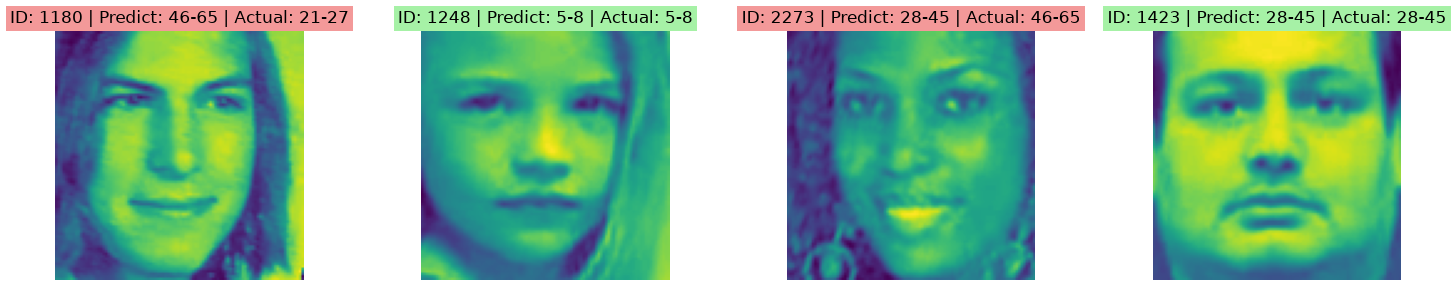

In [42]:
random_ids = np.random.choice(len(X_test), size=4, replace=False)

predictions = simple_model.predict(X_test[random_ids], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(y_test[random_ids], axis=1)
age_group_ranges = ["0-4", "5-8", "9-12", "13-15", "16-17", "18-20", "21-27", "28-45", "46-65", "66+"]

print('Random IDs:', random_ids.tolist())
print('Predicted age groups:', [age_group_ranges[label] for label in predicted_labels])
print('Actual age groups:', [age_group_ranges[label] for label in actual_labels])

fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, image_id, predicted_label, actual_label in zip(axes.flat, random_ids, predicted_labels, actual_labels):
    ax.imshow(X_test[image_id])
    match_color = 'lightgreen' if predicted_label == actual_label else 'lightcoral'
    ax.set_facecolor(match_color)
    title = ax.set_title(
        f'ID: {image_id} | Predict: {age_group_ranges[predicted_label]} | Actual: {age_group_ranges[actual_label]}'
    )
    title.set_bbox(dict(facecolor=match_color, alpha=0.8, edgecolor='none', pad=3))
    ax.axis('off')

plt.tight_layout()
plt.show()

# Complex CNN with VGG16

In [43]:
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

In [44]:
IMG_SIZE = 128
BATCH_SIZE = 64

test_datagen = ImageDataGenerator()

train_generator = train_datagen.flow(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_generator = test_datagen.flow(
    X_test, y_test,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [45]:
vgg_base = VGG16(
    weights='imagenet', 
    include_top=False, 
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
vgg_base.trainable = False  # Freeze base model

vgg_model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
    layers.Resizing(IMG_SIZE, IMG_SIZE),    # Resize with batch
    layers.Lambda(tf.image.grayscale_to_rgb), # Expand only the current batch for VGG16
    layers.Rescaling(255.0),                 # X is normalized to [0, 1] above
    layers.Lambda(vgg_preprocess),          # Applied onto the input before the backbone 
    vgg_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

vgg_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,586 (56.64 MB)

 Trainable params: 133,898 (523.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [46]:
vgg_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'])

In [47]:
history_vgg = vgg_model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20


I0000 00:00:1792120721.556002    4551 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
W0000 00:00:1792120722.379911    5326 assert_op.cc:39] Ignoring Assert operator sequential_1_1/lambda_1/grayscale_to_rgb/assert_equal_1/Assert/Assert
W0000 00:00:1792120722.380126    5326 assert_op.cc:39] Ignoring Assert operator sequential_1_1/lambda_1/grayscale_to_rgb/assert_greater_equal/Assert/Assert
I0000 00:00:1792120722.712782    5326 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_34010__.81
I0000 00:00:1792120724.338448    5326 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1792120724.821083    5326 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set 

131/297 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.3313 - loss: 3.3304

W0000 00:00:1792120731.248581    5328 assert_op.cc:39] Ignoring Assert operator sequential_1_1/lambda_1/grayscale_to_rgb/assert_equal_1/Assert/Assert
W0000 00:00:1792120731.248635    5328 assert_op.cc:39] Ignoring Assert operator sequential_1_1/lambda_1/grayscale_to_rgb/assert_greater_equal/Assert/Assert
I0000 00:00:1792120731.508250    5328 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_34010__.81


297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.3903 - loss: 2.3040

W0000 00:00:1792120738.635766    5327 assert_op.cc:39] Ignoring Assert operator sequential_1_1/lambda_1/grayscale_to_rgb/assert_equal_1/Assert/Assert
W0000 00:00:1792120738.635879    5327 assert_op.cc:39] Ignoring Assert operator sequential_1_1/lambda_1/grayscale_to_rgb/assert_greater_equal/Assert/Assert
I0000 00:00:1792120738.798579    5327 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
W0000 00:00:1792120740.540964    5324 assert_op.cc:39] Ignoring Assert operator sequential_1_1/lambda_1/grayscale_to_rgb/assert_equal_1/Assert/Assert
W0000 00:00:1792120740.541015    5324 assert_op.cc:39] Ignoring Assert operator sequential_1_1/lambda_1/grayscale_to_rgb/assert_greater_equal/Assert/Assert


297/297 ━━━━━━━━━━━━━━━━━━━━ 21s 50ms/step - accuracy: 0.3903 - loss: 2.3040 - val_accuracy: 0.5070 - val_loss: 1.3198
Epoch 2/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.4799 - loss: 1.3672 - val_accuracy: 0.5116 - val_loss: 1.2629
Epoch 3/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.4935 - loss: 1.3160 - val_accuracy: 0.5280 - val_loss: 1.2394
Epoch 4/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.5017 - loss: 1.2829 - val_accuracy: 0.5289 - val_loss: 1.2360
Epoch 5/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.5101 - loss: 1.2669 - val_accuracy: 0.5365 - val_loss: 1.2300
Epoch 6/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.5132 - loss: 1.2563 - val_accuracy: 0.5318 - val_loss: 1.2214
Epoch 7/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.5123 - loss: 1.2451 - val_accuracy: 0.5352 - val_loss: 1.2280
Epoch 8/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.5126 - loss: 1.2385 - val_accuracy: 0.53

In [48]:
vgg_test_loss, vgg_test_acc = vgg_model.evaluate(test_generator)

print(f"VGG16 test accuracy: {vgg_test_acc:.4f}")

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5432 - loss: 1.2072
VGG16 test accuracy: 0.5432
